## Test Day with pretty ugly data

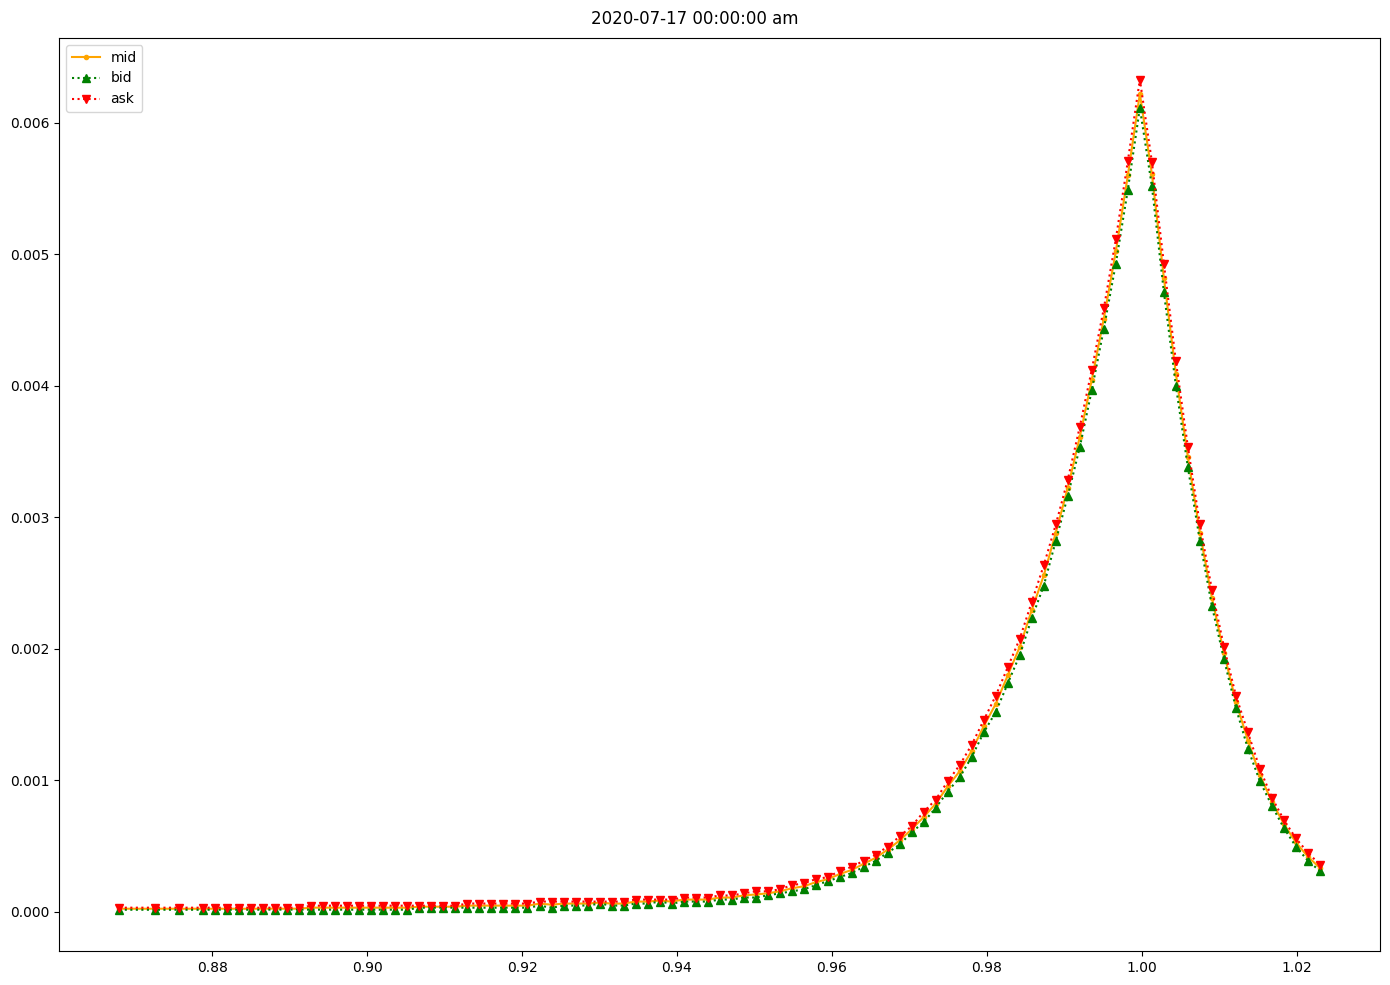

00: SPX 2020-07-15: Generating arb-free price surface.
01:   SPX 2020-07-15: Generated 29 linear arbitrage-free expiries with extended strikes from 29 market expiries. This took 3s.                 
01:   SPX 2020-07-15: Finding linear arbitrage-free mid prices accross the entire surface of 3232 strikes with a minimum strike distance of 0.00155... done. This took 3s.
00: SPX 2020-07-15: generated arbitrage-free price surface. Dropped 0 expiries and 2225 strikes of the remaining expiries. This took 7s.


,spot,spot_prev,date,ticker,call_symbol,put_symbol,call_opt_id,put_opt_id,is_american,is_am,...,pure_fit1_gamma,pure_fit1_vega,pure_fit1_theta,fitX_vol,pure_fitX_price,pure_fitX_delta,pure_fitX_dk,pure_fitX_gamma,pure_fitX_vega,pure_fitX_theta
0,3226.560059,3197.52002,2020-07-15,SPX,SPX 200717C2800000,SPX 200717P2800000,132168806,132168898,False,True,...,0.000000,0.000000,0.000000,0.010000,0.131992,1.000000,-1.000000,0.000000,0.000000,0.000000
1,3226.560059,3197.52002,2020-07-15,SPX,SPX 200717C2815000,SPX 200717P2815000,134227794,134227857,False,True,...,0.000000,0.000000,0.000000,0.010000,0.127342,1.000000,-1.000000,0.000000,0.000000,0.000000
2,3226.560059,3197.52002,2020-07-15,SPX,SPX 200717C2825000,SPX 200717P2825000,132168807,132168899,False,True,...,0.000000,0.000000,0.000000,0.010000,0.124242,1.000000,-1.000000,0.000000,0.000000,0.000000
3,3226.560059,3197.52002,2020-07-15,SPX,SPX 200717C2835000,SPX 200717P2835000,134227795,134227858,False,True,...,0.000000,0.000000,0.000000,0.010000,0.121141,1.000000,-1.000000,0.000000,0.000000,0.000000
4,3226.560059,3197.52002,2020-07-15,SPX,SPX 200717C2840000,SPX 200717P2840000,133485107,133485131,False,True,...,0.000000,0.000000,0.000000,0.010000,0.119591,1.000000,-1.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5394,3226.560059,3197.52002,2020-07-15,SPX,SPX 210618C3800000,SPX 210618P3800000,129499442,129499531,False,True,...,1.493337,0.235543,0.021692,0.166179,0.012009,0.154432,-0.119504,1.486991,0.228672,0.020532
5395,3226.560059,3197.52002,2020-07-15,SPX,SPX 210618C3850000,SPX 210618P3850000,132411391,132411392,False,True,...,1.370427,0.213603,0.019439,0.165376,0.010091,0.134474,-0.103011,1.361117,0.208304,0.018613
5396,3226.560059,3197.52002,2020-07-15,SPX,SPX 210618C3900000,SPX 210618P3900000,129499443,129499532,False,True,...,1.258056,0.197514,0.018106,0.163179,0.008173,0.114158,-0.086649,1.230077,0.185748,0.016377
5397,3226.560059,3197.52002,2020-07-15,SPX,SPX 210618C4000000,SPX 210618P4000000,129499444,129499533,False,True,...,1.048207,0.166092,0.015366,0.170236,0.006941,0.096335,-0.071258,1.042747,0.164270,0.015109


In [1]:
if False:
    import os
    os.environ["QUANTDATA_CACHE_MODE"] = "off" # turns off global cache mode; good for testing, but do not use in general.

%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.sanos.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree

from datetime import date

from cdxcore.dynaplot import figure
from quantdata.widb.day import collect_raw_day, enrich_day, ExpiryFilter, RawDayFilter
from quantdata.widb.arbfree import mk_arb_free_day, MkArbFree
from quantdata.biz_calendar import next_business_day, DAYS_PER_YEAR
from cdxcore.verbose import Context
from IPython.display import display
import numpy as np

def test():
    ticker = "SPX"
    d      = next_business_day( date(2020, 7, 15), count_start=True )

    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    verbose = Context.all

    raw_day = collect_raw_day(ticker, d, raw_day_filter=raw_day_filter, verbose=verbose, raise_if_bad_day=False)

    enr_day = enrich_day(ticker, d, raw_day, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False)

    expiry_ids = enr_day['expiry_id'].to_numpy()
    unids = np.unique( expiry_ids )

    BAD_UID = 202007170

    """
    with figure("Expiries", row_size=3, col_size=4, columns=4) as fig:
        for uid in unids:
            tte_y = enr_day['tte_y'][ expiry_ids == uid ].iloc[0]

            mask = enr_day['expiry_id'] == uid
            strikes = enr_day['pure_strike'][mask].to_numpy()
            bids = enr_day['pure_bid_price'][mask].to_numpy()
            asks = enr_day['pure_ask_price'][mask].to_numpy()
            mids = (bids + asks) / 2.

            dC = np.diff( mids, prepend=1. ) / np.diff( strikes, prepend=0. )
            p  = np.diff( mids, append=0.) 

            ok = np.all(p>=-1E-6) and abs(np.sum(p)-1) < 1E-6 and abs(p@strikes-1.) < 1E-6
            ax = fig.add_subplot(f"{uid} {tte_y*DAYS_PER_YEAR:.1f}d {'ok' if ok else 'not ok'}")
            ax.plot(strikes, dC, label="market dC")
            ax.plot(strikes, strikes*0-1., ":", color="black")
            ax.plot(strikes, strikes*0, ":", color="black")
            ax.legend(loc="upper left")
            ax2 = ax.twinx()
            ax2.plot(strikes, p, label="market p", color="orange")
            ax.plot(strikes, strikes*0-1., ":", color="red")
            ax.plot(strikes, strikes*0, ":", color="red")
            ax2.legend(loc="upper right")
    """


    mask = enr_day['expiry_id'] == BAD_UID
    tte_y = enr_day['tte_y'][ mask].iloc[0]
    expiry = enr_day['expiry'][ mask].iloc[0]
    is_am = enr_day['is_am'][ mask].iloc[0]
    strikes = enr_day['pure_strike'][mask].to_numpy()
    bids = enr_day['pure_bid_price'][mask].to_numpy()
    asks = enr_day['pure_ask_price'][mask].to_numpy()
    mids = (bids + asks) / 2.
    intr = np.maximum( 0., 1. - strikes )
    
    with figure(f"{expiry} {'am' if is_am else 'pm'}", row_size=10, col_size=14, columns=1) as fig:
        ax = fig.add_subplot()

        ax.plot(strikes, mids-intr, ".-", color="orange", label="mid")
        ax.plot(strikes, bids-intr,"^:", color="green", label="bid")
        ax.plot(strikes, asks-intr, "v:", color="red", label="ask")
        ax.legend(loc="upper left")



    arb_free = MkArbFree(timeout_seconds_expiry=500)
    arb_free = mk_arb_free_day(ticker, d, enr_day, mk_arb_free=arb_free, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False, override_cache_mode="off")

    display(arb_free)
    return arb_free

_ = test()